In [2]:
!pip install pyfixest[jax]

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.7/115.7 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 23.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 18.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 16.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 607.2/607.2 kB 19.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 85.0/85.0 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 332.3/332.3 kB 7.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 1.7 MB/s eta 0:00:00


In [3]:
!pip install linearmodels

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 14.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.9/43.9 kB 2.4 MB/s eta 0:00:00


In [4]:
import pandas as pd
import statsmodels.formula.api as smf
import seaborn as sns
import matplotlib.pyplot as plt
from pyfixest.estimation import feols
import scipy.stats
import numpy as np
from matplotlib.lines import Line2D
import linearmodels as lm



from google.colab import drive
drive.mount('/content/gdrive')

attendance_df = pd.read_csv(r'/content/gdrive/My Drive/ECON 692/WNBA All Game Attendance - All Game Attendance.csv')

Mounted at /content/gdrive


In [5]:
attendance_df.head()

,Unnamed: 0,Year,Day of Week,Month,Day,Time (ET),Game Type,Home Team,Away Team,Arena,City,State,Attendance
0,1,1997,Saturday,June,21,4:00 PM,Regular season,Los Angeles Sparks,New York Liberty,Great Western Forum,Los Angeles,CA,14284
1,2,1997,Saturday,June,21,7:00 PM,Regular season,Cleveland Rockers,Houston Comets,Quicken Loans Arena,Cleveland,OH,11455
2,3,1997,Saturday,June,21,5:00 AM,Regular season,Utah Starzz,Sacramento Monarchs,EnergySolutions Arena,Salt Lake City,UT,8915
3,4,1997,Sunday,June,22,4:00 PM,Regular season,Phoenix Mercury,Charlotte Sting,US Airways Center,Phoenix,AZ,16102
4,5,1997,Monday,June,23,3:00 AM,Regular season,Utah Starzz,Los Angeles Sparks,EnergySolutions Arena,Salt Lake City,UT,8036


                          PanelOLS Estimation Summary                           
Dep. Variable:             Attendance   R-squared:                        0.0185
Estimator:                   PanelOLS   R-squared (Between):              0.0039
No. Observations:                6214   R-squared (Within):               0.0039
Date:                Thu, Apr 10 2025   R-squared (Overall):              0.0091
Time:                        02:59:15   Log-likelihood                -5.783e+04
Cov. Estimator:             Clustered                                           
                                        F-statistic:                      12.866
Entities:                          29   P-value                           0.0000
Avg Obs:                       214.28   Distribution:                  F(9,6150)
Min Obs:                       1.0000                                           
Max Obs:                       503.00   F-statistic (robust):             143.39
                            

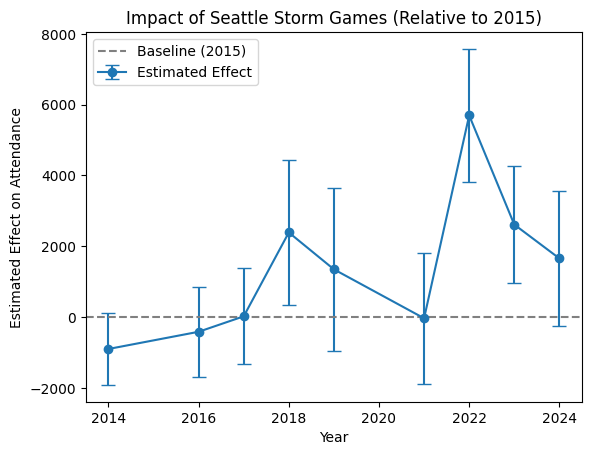

In [9]:
# Seattle Storm (Jewell Loyd; 2015-2024)
st_attendance_df = attendance_df.copy()

# 🚀 2. Create Treatment Variable for Storm Games (2015-2024)
st_attendance_df['ST_Storm_Game'] = (st_attendance_df['Home Team'] == 'Seattle Storm') & (st_attendance_df['Year'].between(2014, 2024))

# 🚀 3. Create Interaction Terms for Each Year (Skip 2015 as the Reference; no data for 2020 (COVID year) so I will also omit it)
for year in [2014, 2016, 2017, 2018, 2019, 2021, 2022, 2023, 2024]:
    col_name = f'INX{year}'
    st_attendance_df[col_name] = st_attendance_df['ST_Storm_Game'].astype(int)
    st_attendance_df.loc[st_attendance_df['Year'] != year, col_name] = 0

# 🚀 4. Set Index for Panel Data (Team and Year)
st_attendance_df = st_attendance_df.set_index(['Home Team', 'Year'])

# 🚀 5. Define and Fit Panel Regression Model
mod = lm.PanelOLS.from_formula(
    'Attendance ~ INX2014 + INX2016 + INX2017 + INX2018 + INX2019 + INX2021 + INX2022 + INX2023 + INX2024 + EntityEffects + TimeEffects - TimeEffects[2015]',
    st_attendance_df
)
clfe = mod.fit(cov_type='clustered', cluster_entity=True)
print(clfe.summary)

# 🚀 6. Extract Coefficients and Confidence Intervals
res = pd.concat([clfe.params, clfe.std_errors], axis=1)
res.columns = ['parameter', 'std_error']
res['ci'] = res['std_error'] * 1.96  # 95% CI
res['Year'] = [2014, 2016, 2017, 2018, 2019, 2021, 2022, 2023, 2024]  # Excluding 2015 as the reference

# Print results table
print("\n📊 Coefficients & Confidence Intervals:")
print(res)

# 🚀 7. Plot the Results
plt.errorbar(x=res['Year'], y=res['parameter'], yerr=res['ci'], fmt='o-', capsize=5, label="Estimated Effect")
plt.axhline(0, linestyle='dashed', color='gray', label="Baseline (2015)")
plt.xlabel("Year")
plt.ylabel("Estimated Effect on Attendance")
plt.title("Impact of Seattle Storm Games (Relative to 2015)")
plt.legend()
plt.show()


                          PanelOLS Estimation Summary                           
Dep. Variable:             Attendance   R-squared:                        0.0173
Estimator:                   PanelOLS   R-squared (Between):              0.0034
No. Observations:                6214   R-squared (Within):               0.0011
Date:                Thu, Apr 10 2025   R-squared (Overall):              0.0076
Time:                        03:02:51   Log-likelihood                -5.784e+04
Cov. Estimator:             Clustered                                           
                                        F-statistic:                      15.483
Entities:                          29   P-value                           0.0000
Avg Obs:                       214.28   Distribution:                  F(7,6152)
Min Obs:                       1.0000                                           
Max Obs:                       503.00   F-statistic (robust):             55.091
                            

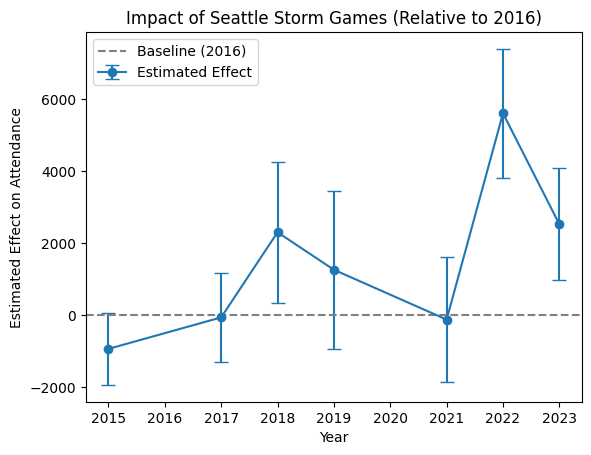

In [10]:
# Seattle Storm (Breanna Stewart; 2016-2023)
st_attendance_df = attendance_df.copy()

# 🚀 2. Create Treatment Variable for Storm Games (2016-2023)
st_attendance_df['ST_Storm_Game'] = (st_attendance_df['Home Team'] == 'Seattle Storm') & (st_attendance_df['Year'].between(2015, 2023))

# 🚀 3. Create Interaction Terms for Each Year (Skip 2016 as the Reference; no data for 2020 (COVID year) so I will also omit it)
for year in [2015, 2017, 2018, 2019, 2021, 2022, 2023]:
    col_name = f'INX{year}'
    st_attendance_df[col_name] = st_attendance_df['ST_Storm_Game'].astype(int)
    st_attendance_df.loc[st_attendance_df['Year'] != year, col_name] = 0

# 🚀 4. Set Index for Panel Data (Team and Year)
st_attendance_df = st_attendance_df.set_index(['Home Team', 'Year'])

# 🚀 5. Define and Fit Panel Regression Model
mod = lm.PanelOLS.from_formula(
    'Attendance ~ INX2015 + INX2017 + INX2018 + INX2019 + INX2021 + INX2022 + INX2023 + EntityEffects + TimeEffects - TimeEffects[2016]',
    st_attendance_df
)
clfe = mod.fit(cov_type='clustered', cluster_entity=True)
print(clfe.summary)

# 🚀 6. Extract Coefficients and Confidence Intervals
res = pd.concat([clfe.params, clfe.std_errors], axis=1)
res.columns = ['parameter', 'std_error']
res['ci'] = res['std_error'] * 1.96  # 95% CI
res['Year'] = [2015, 2017, 2018, 2019, 2021, 2022, 2023]  # Excluding 2016 as the reference

# Print results table
print("\n📊 Coefficients & Confidence Intervals:")
print(res)

# 🚀 7. Plot the Results
plt.errorbar(x=res['Year'], y=res['parameter'], yerr=res['ci'], fmt='o-', capsize=5, label="Estimated Effect")
plt.axhline(0, linestyle='dashed', color='gray', label="Baseline (2016)")
plt.xlabel("Year")
plt.ylabel("Estimated Effect on Attendance")
plt.title("Impact of Seattle Storm Games (Relative to 2016)")
plt.legend()
plt.show()


                          PanelOLS Estimation Summary                           
Dep. Variable:             Attendance   R-squared:                        0.0175
Estimator:                   PanelOLS   R-squared (Between):              0.0038
No. Observations:                6214   R-squared (Within):               0.0044
Date:                Thu, Apr 10 2025   R-squared (Overall):              0.0090
Time:                        03:08:35   Log-likelihood                -5.784e+04
Cov. Estimator:             Clustered                                           
                                        F-statistic:                      21.886
Entities:                          29   P-value                           0.0000
Avg Obs:                       214.28   Distribution:                  F(5,6154)
Min Obs:                       1.0000                                           
Max Obs:                       503.00   F-statistic (robust):             60.613
                            

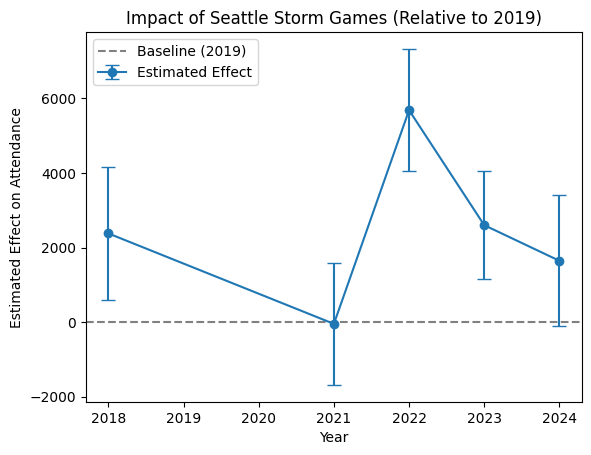

In [11]:
# Seattle Storm (Ezi Magbegor; 2019-2024)
st_attendance_df = attendance_df.copy()

# 🚀 2. Create Treatment Variable for Storm Games (2019-2024)
st_attendance_df['ST_Storm_Game'] = (st_attendance_df['Home Team'] == 'Seattle Storm') & (st_attendance_df['Year'].between(2018, 2024))

# 🚀 3. Create Interaction Terms for Each Year (Skip 2019 as the Reference; no data for 2020 (COVID year) so I will also omit it)
for year in [2018, 2021, 2022, 2023, 2024]:
    col_name = f'INX{year}'
    st_attendance_df[col_name] = st_attendance_df['ST_Storm_Game'].astype(int)
    st_attendance_df.loc[st_attendance_df['Year'] != year, col_name] = 0

# 🚀 4. Set Index for Panel Data (Team and Year)
st_attendance_df = st_attendance_df.set_index(['Home Team', 'Year'])

# 🚀 5. Define and Fit Panel Regression Model
mod = lm.PanelOLS.from_formula(
    'Attendance ~ INX2018 + INX2021 + INX2022 + INX2023 + INX2024 + EntityEffects + TimeEffects - TimeEffects[2019]',
    st_attendance_df
)
clfe = mod.fit(cov_type='clustered', cluster_entity=True)
print(clfe.summary)

# 🚀 6. Extract Coefficients and Confidence Intervals
res = pd.concat([clfe.params, clfe.std_errors], axis=1)
res.columns = ['parameter', 'std_error']
res['ci'] = res['std_error'] * 1.96  # 95% CI
res['Year'] = [2018, 2021, 2022, 2023, 2024]  # Excluding 2019 as the reference

# Print results table
print("\n📊 Coefficients & Confidence Intervals:")
print(res)

# 🚀 7. Plot the Results
plt.errorbar(x=res['Year'], y=res['parameter'], yerr=res['ci'], fmt='o-', capsize=5, label="Estimated Effect")
plt.axhline(0, linestyle='dashed', color='gray', label="Baseline (2019)")
plt.xlabel("Year")
plt.ylabel("Estimated Effect on Attendance")
plt.title("Impact of Seattle Storm Games (Relative to 2019)")
plt.legend()
plt.show()
